1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler

# Plot style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

2. Load Dataset

In [ ]:
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/econmath.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


3. View Dataset

In [ ]:
df.head()
df.tail()
df.shape
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 856 entries, 0 to 855
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  856 non-null    int64  
 1   age       856 non-null    int64  
 2   work      856 non-null    float64
 3   study     856 non-null    float64
 4   econhs    856 non-null    int64  
 5   colgpa    856 non-null    float64
 6   hsgpa     856 non-null    float64
 7   acteng    814 non-null    float64
 8   actmth    814 non-null    float64
 9   act       814 non-null    float64
 10  mathscr   856 non-null    int64  
 11  male      856 non-null    int64  
 12  calculus  856 non-null    int64  
 13  attexc    856 non-null    int64  
 14  attgood   856 non-null    int64  
 15  fathcoll  856 non-null    int64  
 16  mothcoll  856 non-null    int64  
 17  score     856 non-null    float64
dtypes: float64(8), int64(10)
memory usage: 120.5 KB


4. Basic Statistical Analysis

In [ ]:
df.describe()
df.describe(include='all')
df.dtypes
df.nunique()

,0
rownames,856
age,9
work,44
study,52
econhs,2
colgpa,612
hsgpa,531
acteng,23
actmth,23
act,20


5. Check Missing Values

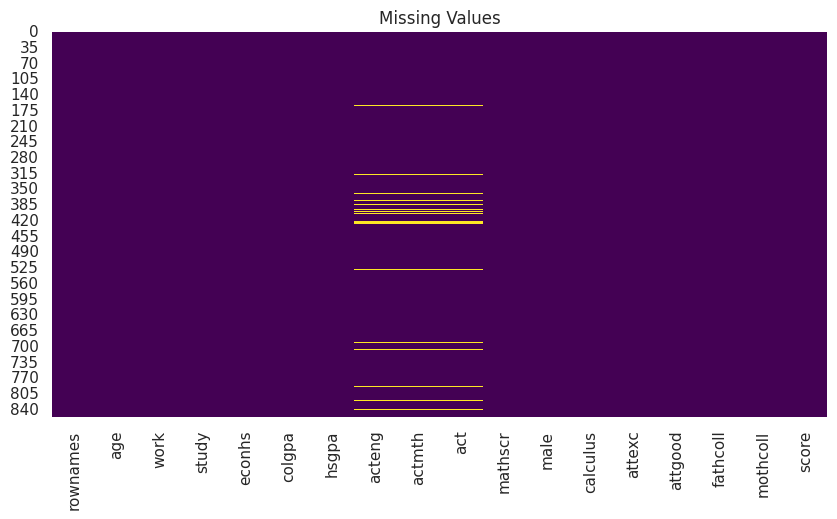

In [ ]:
df.isnull().sum()
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(),cbar=False,cmap="viridis")
plt.title("Missing Values")
plt.show()

6. Handle Missing Values

In [ ]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col].fillna(df[col].median(), inplace=True)

categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    df[col].fillna(df[col].mode()[0], inplace=True)
df.isnull().sum()

/tmp/ipykernel_1710/3738852434.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


,0
rownames,0
age,0
work,0
study,0
econhs,0
colgpa,0
hsgpa,0
acteng,0
actmth,0
act,0


7. Remove Duplicate Records

In [ ]:
print("Duplicates :",df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicates after removing :",df.duplicated().sum())

Duplicates : 0
Duplicates after removing : 0


8. Data Transformation

In [ ]:
#Label Encoding
le = LabelEncoder()

for col in categorical_columns:
    df[col]=le.fit_transform(df[col])

#Feature Scaling
scaler=StandardScaler()

df_scaled=df.copy()

df_scaled[numeric_columns]=scaler.fit_transform(df[numeric_columns])

df_scaled.head()



,rownames,age,work,study,econhs,colgpa,hsgpa,acteng,actmth,act,mathscr,male,calculus,attexc,attgood,fathcoll,mothcoll,score
0,-1.730029,3.837667,0.691135,-0.502317,-0.766894,1.260292,0.036623,0.375134,0.761103,1.190058,1.227916,1.0,0.691673,-0.649559,-1.190831,0.952081,0.768816,0.883321
1,-1.725982,3.837667,-0.935215,1.100280,1.303961,-1.331995,-0.359615,0.104380,-0.870377,0.270939,0.650073,1.0,-1.445771,-0.649559,-1.190831,-1.050330,0.768816,-1.136413
2,-1.721935,1.701749,1.775369,-0.245901,-0.766894,0.503983,-0.106139,-0.437129,0.217277,-0.648179,0.072230,1.0,0.691673,1.539506,-1.190831,-1.050330,0.768816,-0.463666
3,-1.717888,2.769708,2.317485,3.343917,-0.766894,-0.250090,1.848831,2.270414,1.304930,2.415549,1.227916,-1.0,0.691673,-0.649559,0.839750,0.952081,0.768816,0.638414
4,-1.713841,2.769708,1.775369,0.138722,1.303961,1.734616,1.595355,1.458151,2.120670,2.721922,0.072230,1.0,0.691673,-0.649559,0.839750,-1.050330,0.768816,1.739748


9. Univariate Analysis (3 Visualizations)

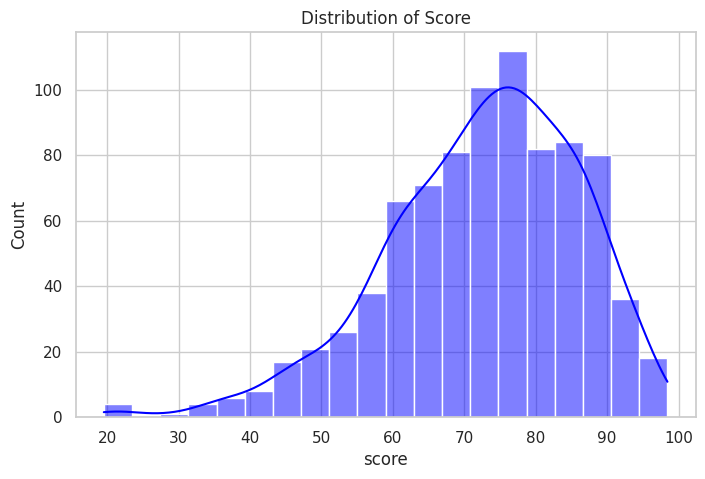

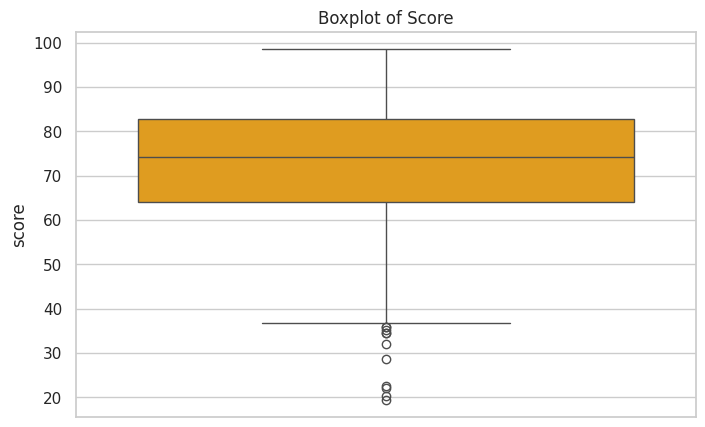

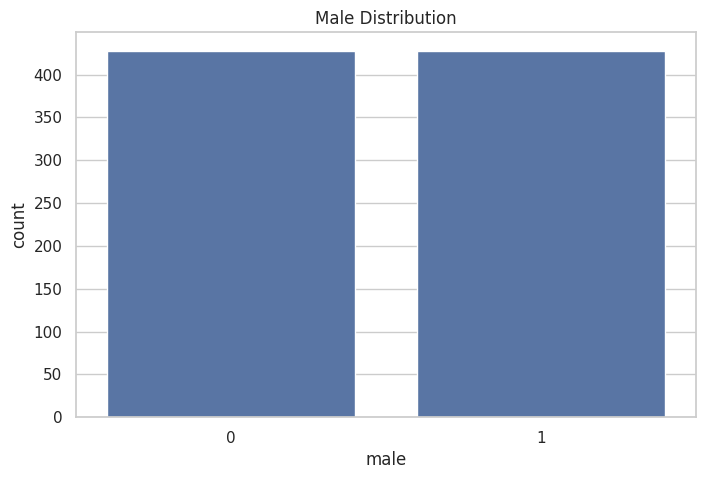

In [ ]:
#Histogram
plt.figure(figsize=(8,5))
sns.histplot(df["score"],bins=20,kde=True,color="blue")
plt.title("Distribution of Score")
plt.show()

#Boxplot
plt.figure(figsize=(8,5))
sns.boxplot(y=df["score"],color="orange")
plt.title("Boxplot of Score")
plt.show()

#Countplot
plt.figure(figsize=(8,5))
sns.countplot(x=df["male"])
plt.title("Male Distribution")
plt.show()

10. Bivariate Analysis (3 Visualizations)

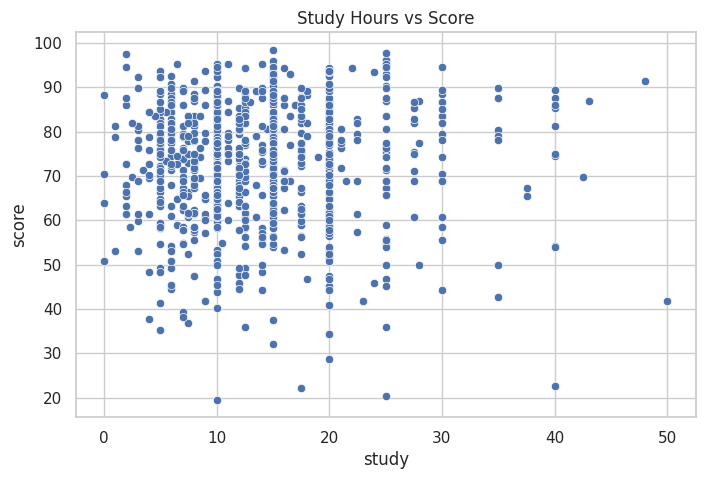

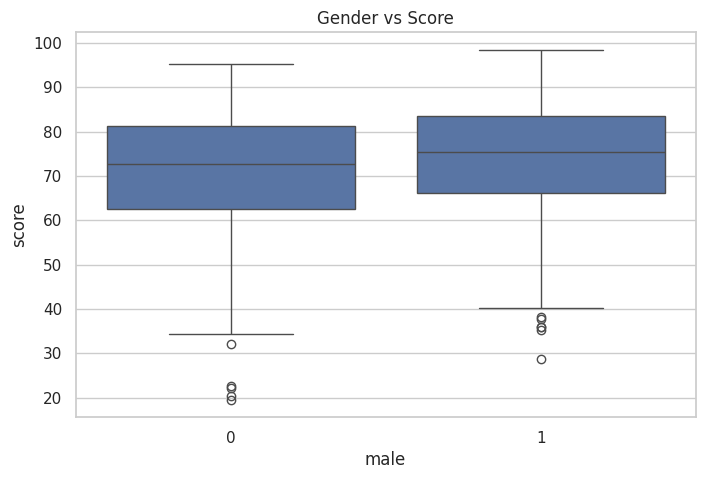

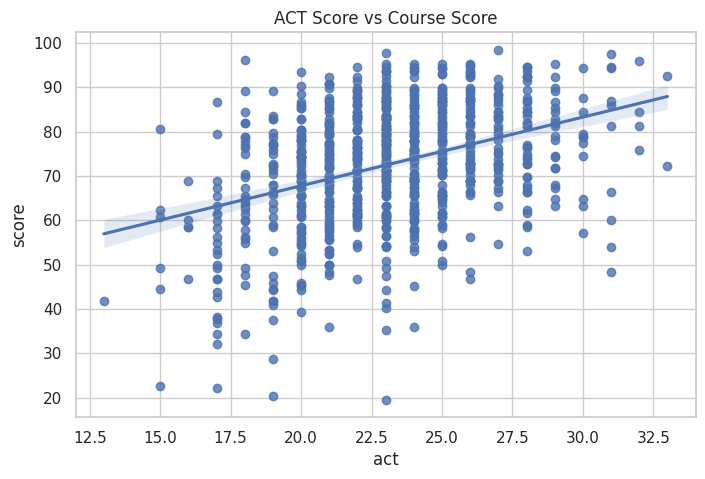

In [ ]:
#Scatter plot
plt.figure(figsize=(8,5))
sns.scatterplot(x="study",y="score",data=df)
plt.title("Study Hours vs Score")
plt.show()

#Box plot
plt.figure(figsize=(8,5))
sns.boxplot(x="male",y="score",data=df)
plt.title("Gender vs Score")
plt.show()

#Regression plot
plt.figure(figsize=(8,5))
sns.regplot(x="act",y="score",data=df)
plt.title("ACT Score vs Course Score")
plt.show()

11. Multivariate Analysis (3 Visualizations)

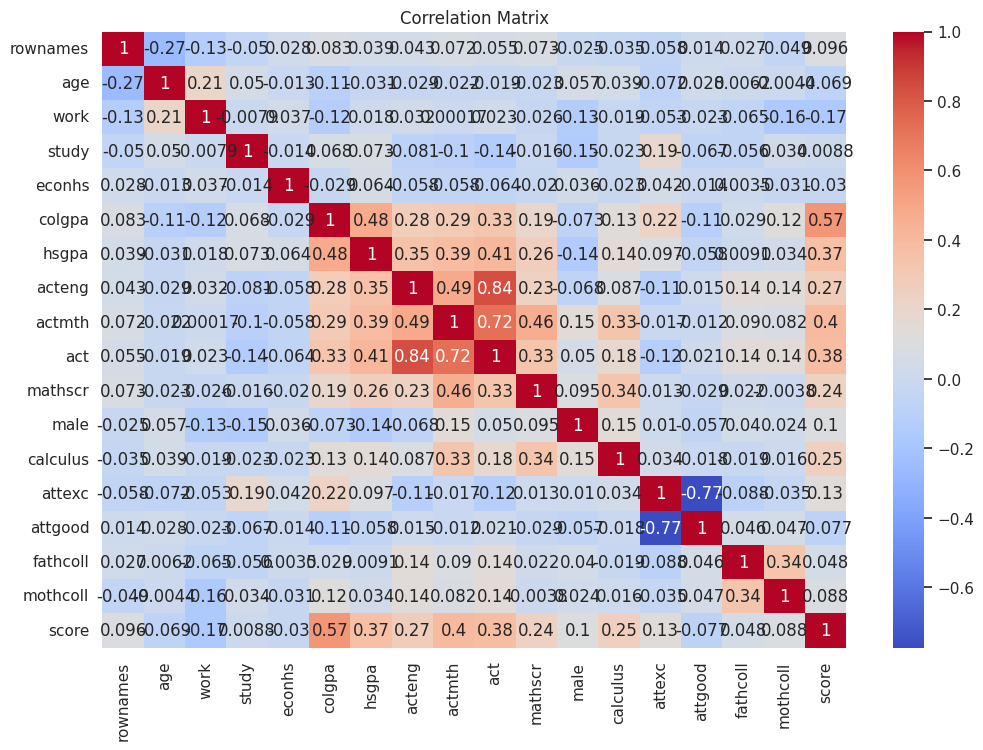

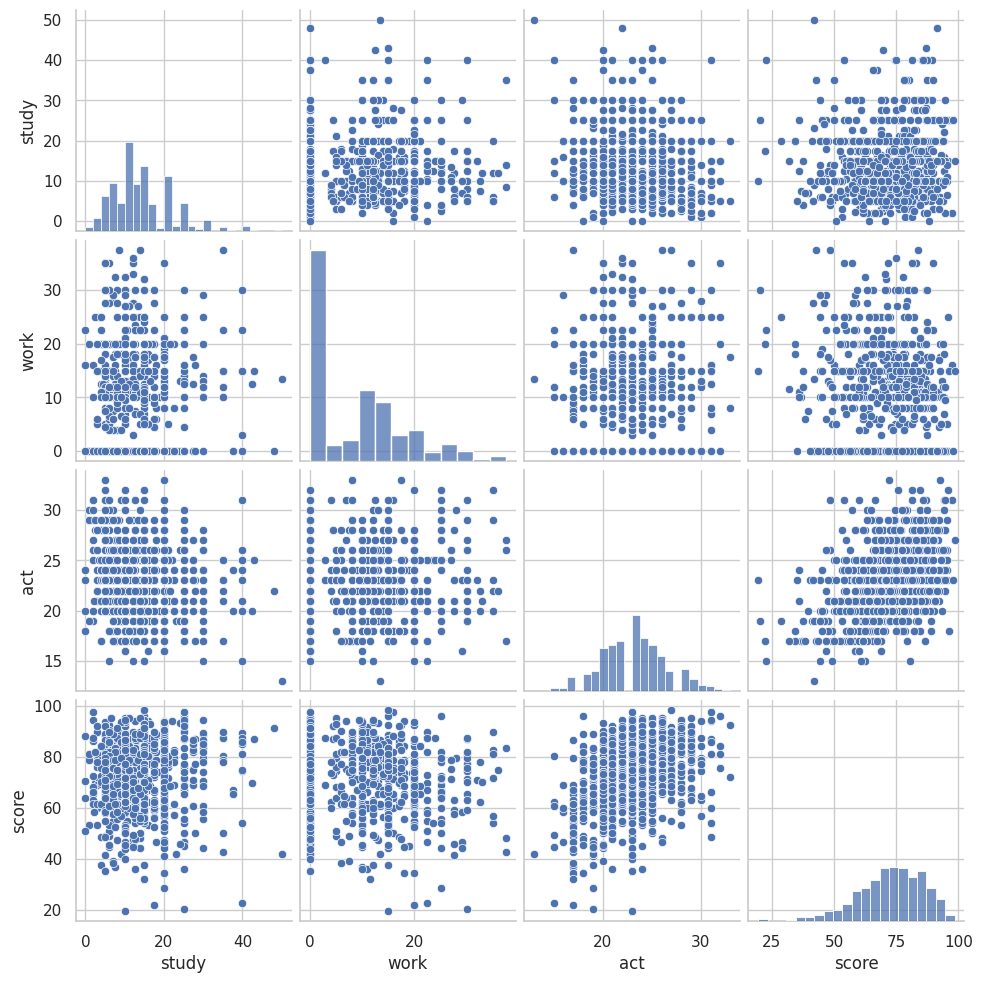

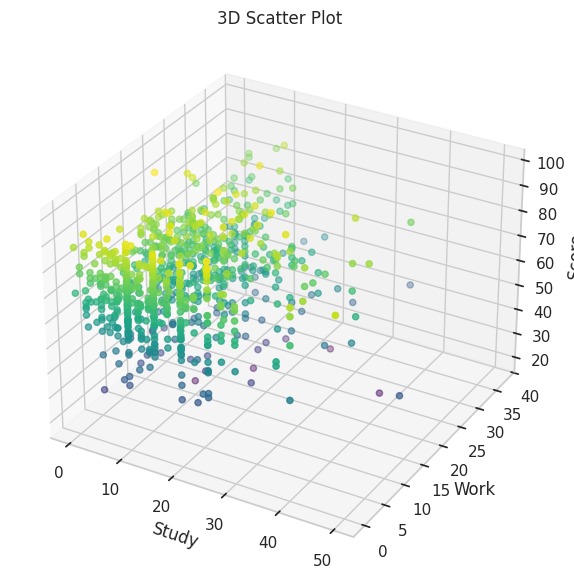

In [ ]:
#Correlation Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

#Pair plot
sns.pairplot(df[['study','work','act','score']])
plt.show()

#3D Scatter Plot
from mpl_toolkits.mplot3d import Axes3D

fig=plt.figure(figsize=(10,7))

ax=fig.add_subplot(111,projection='3d')

ax.scatter(df['study'],
           df['work'],
           df['score'],
           c=df['score'],
           cmap='viridis')

ax.set_xlabel("Study")

ax.set_ylabel("Work")

ax.set_zlabel("Score")

plt.title("3D Scatter Plot")
plt.show()

#

12. Outlier Detection

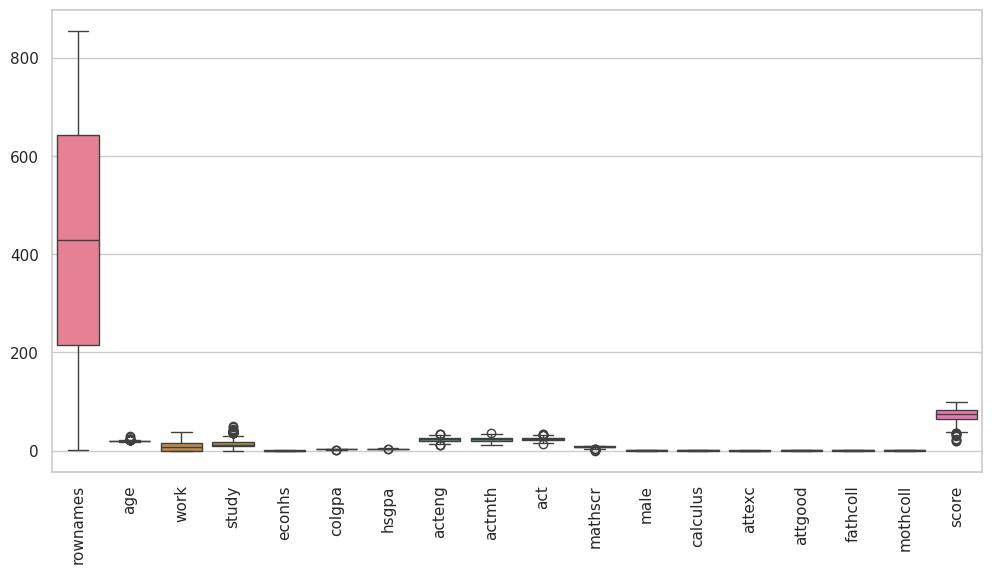

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df[numeric_columns])

plt.xticks(rotation=90)

plt.show()

13. Correlation with Target

In [ ]:
corr=df.corr()

corr["score"].sort_values(ascending=False)

,score
score,1.000000
colgpa,0.573519
actmth,0.395067
act,0.377270
hsgpa,0.367549
acteng,0.268210
calculus,0.251967
mathscr,0.244440
attexc,0.128161
male,0.100331


14. Final Dataset

In [ ]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 856 entries, 0 to 855
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  856 non-null    int64  
 1   age       856 non-null    int64  
 2   work      856 non-null    float64
 3   study     856 non-null    float64
 4   econhs    856 non-null    int64  
 5   colgpa    856 non-null    float64
 6   hsgpa     856 non-null    float64
 7   acteng    856 non-null    float64
 8   actmth    856 non-null    float64
 9   act       856 non-null    float64
 10  mathscr   856 non-null    int64  
 11  male      856 non-null    int64  
 12  calculus  856 non-null    int64  
 13  attexc    856 non-null    int64  
 14  attgood   856 non-null    int64  
 15  fathcoll  856 non-null    int64  
 16  mothcoll  856 non-null    int64  
 17  score     856 non-null    float64
dtypes: float64(8), int64(10)
memory usage: 120.5 KB


15. Conclusion

In [ ]:
print("""
EDA Completed Successfully

1. Dataset Loaded
2. Statistical Summary Generated
3. Missing Values Handled
4. Duplicate Records Removed
5. Data Transformed
6. Univariate Analysis Completed
7. Bivariate Analysis Completed
8. Multivariate Analysis Completed
""")


EDA Completed Successfully

1. Dataset Loaded
2. Statistical Summary Generated
3. Missing Values Handled
4. Duplicate Records Removed
5. Data Transformed
6. Univariate Analysis Completed
7. Bivariate Analysis Completed
8. Multivariate Analysis Completed



Import libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

from mpl_toolkits.mplot3d import Axes3D

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

17. Load dataset


In [ ]:
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/econmath.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Loaded Successfully

First 5 Records:


,rownames,age,work,study,econhs,colgpa,hsgpa,acteng,actmth,act,mathscr,male,calculus,attexc,attgood,fathcoll,mothcoll,score
0,1,23,15.0,10.0,0,3.4909,3.355,24.0,26.0,27.0,10,1,1,0,0,1,1,84.43
1,2,23,0.0,22.5,1,2.1000,3.219,23.0,20.0,24.0,9,1,0,0,0,0,1,57.38
2,3,21,25.0,12.0,0,3.0851,3.306,21.0,24.0,21.0,8,1,1,1,0,0,1,66.39
3,4,22,30.0,40.0,0,2.6805,3.977,31.0,28.0,31.0,10,0,1,0,1,1,1,81.15
4,5,22,25.0,15.0,1,3.7454,3.890,28.0,31.0,32.0,8,1,1,0,1,0,1,95.90



Dataset Shape:
(856, 18)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 856 entries, 0 to 855
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  856 non-null    int64  
 1   age       856 non-null    int64  
 2   work      856 non-null    float64
 3   study     856 non-null    float64
 4   econhs    856 non-null    int64  
 5   colgpa    856 non-null    float64
 6   hsgpa     856 non-null    float64
 7   acteng    814 non-null    float64
 8   actmth    814 non-null    float64
 9   act       814 non-null    float64
 10  mathscr   856 non-null    int64  
 11  male      856 non-null    int64  
 12  calculus  856 non-null    int64  
 13  attexc    856 non-null    int64  
 14  attgood   856 non-null    int64  
 15  fathcoll  856 non-null    int64  
 16  mothcoll  856 non-null    int64  
 17  score     856 non-null    float64
dtypes: float64(8), int64(10)
memory usage: 120.5 KB

Statistical S

,rownames,age,work,study,econhs,colgpa,hsgpa,acteng,actmth,act,mathscr,male,calculus,attexc,attgood,fathcoll,mothcoll,score
count,856.000000,856.000000,856.000000,856.000000,856.000000,856.000000,856.000000,814.000000,814.000000,814.000000,856.000000,856.000000,856.000000,856.000000,856.000000,856.000000,856.000000,856.000000
mean,428.500000,19.406542,8.625584,13.917991,0.370327,2.814686,3.342430,22.594595,23.211302,23.121622,7.875000,0.500000,0.676402,0.296729,0.586449,0.524533,0.628505,72.599813
std,247.250211,0.936913,9.228500,7.804398,0.483175,0.536867,0.343428,3.788735,3.773354,3.349094,1.731587,0.500292,0.468122,0.457083,0.492758,0.499690,0.483487,13.400678
min,1.000000,18.000000,0.000000,0.000000,0.000000,0.875000,2.355000,12.000000,12.000000,13.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,19.530000
25%,214.750000,19.000000,0.000000,8.500000,0.000000,2.445900,3.110000,20.000000,20.000000,21.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,64.060000
50%,428.500000,19.000000,8.000000,12.000000,0.000000,2.812900,3.321500,23.000000,23.000000,23.000000,8.000000,0.500000,1.000000,0.000000,1.000000,1.000000,1.000000,74.220000
75%,642.250000,20.000000,15.000000,18.000000,1.000000,3.206900,3.589000,25.000000,26.000000,25.000000,9.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,82.790000
max,856.000000,29.000000,37.500000,50.000000,1.000000,4.000000,4.260000,34.000000,36.000000,33.000000,10.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,98.440000


18. Data Cleaning

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Handle missing values
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
display(df.head())

Missing Values:
rownames     0
age          0
work         0
study        0
econhs       0
colgpa       0
hsgpa        0
acteng      42
actmth      42
act         42
mathscr      0
male         0
calculus     0
attexc       0
attgood      0
fathcoll     0
mothcoll     0
score        0
dtype: int64

Duplicate Records:
0

Missing Values After Cleaning:
rownames    0
age         0
work        0
study       0
econhs      0
colgpa      0
hsgpa       0
acteng      0
actmth      0
act         0
mathscr     0
male        0
calculus    0
attexc      0
attgood     0
fathcoll    0
mothcoll    0
score       0
dtype: int64

Cleaned Dataset:


,rownames,age,work,study,econhs,colgpa,hsgpa,acteng,actmth,act,mathscr,male,calculus,attexc,attgood,fathcoll,mothcoll,score
0,1,23,15.0,10.0,0,3.4909,3.355,24.0,26.0,27.0,10,1,1,0,0,1,1,84.43
1,2,23,0.0,22.5,1,2.1000,3.219,23.0,20.0,24.0,9,1,0,0,0,0,1,57.38
2,3,21,25.0,12.0,0,3.0851,3.306,21.0,24.0,21.0,8,1,1,1,0,0,1,66.39
3,4,22,30.0,40.0,0,2.6805,3.977,31.0,28.0,31.0,10,0,1,0,1,1,1,81.15
4,5,22,25.0,15.0,1,3.7454,3.890,28.0,31.0,32.0,8,1,1,0,1,0,1,95.90


19. Data Handling


In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

# Convert binary categorical variables
categorical_columns = [
    'male', 'calculus', 'econhs',
    'attexc', 'attgood', 'fathcoll', 'mothcoll'
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].astype('category')

print("\nUpdated Data Types:")
print(df.dtypes)

Column Names:
['rownames', 'age', 'work', 'study', 'econhs', 'colgpa', 'hsgpa', 'acteng', 'actmth', 'act', 'mathscr', 'male', 'calculus', 'attexc', 'attgood', 'fathcoll', 'mothcoll', 'score']

Data Types:
rownames      int64
age           int64
work        float64
study       float64
econhs        int64
colgpa      float64
hsgpa       float64
acteng      float64
actmth      float64
act         float64
mathscr       int64
male          int64
calculus      int64
attexc        int64
attgood       int64
fathcoll      int64
mothcoll      int64
score       float64
dtype: object

Updated Data Types:
rownames       int64
age            int64
work         float64
study        float64
econhs      category
colgpa       float64
hsgpa        float64
acteng       float64
actmth       float64
act          float64
mathscr        int64
male        category
calculus    category
attexc      category
attgood     category
fathcoll    category
mothcoll    category
score        float64
dtype: object


20.1D Statistical Analysis

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

print("Mean:")
display(numeric_df.mean())

print("\nMedian:")
display(numeric_df.median())

print("\nMode:")
display(numeric_df.mode().iloc[0])

print("\nStandard Deviation:")
display(numeric_df.std())

print("\nVariance:")
display(numeric_df.var())

print("\nMinimum:")
display(numeric_df.min())

print("\nMaximum:")
display(numeric_df.max())

Mean:


,0
rownames,428.500000
age,19.406542
work,8.625584
study,13.917991
colgpa,2.814686
hsgpa,3.342430
acteng,22.614486
actmth,23.200935
act,23.115654
mathscr,7.875000



Median:


,0
rownames,428.5000
age,19.0000
work,8.0000
study,12.0000
colgpa,2.8129
hsgpa,3.3215
acteng,23.0000
actmth,23.0000
act,23.0000
mathscr,8.0000



Mode:


,0
rownames,1.00
age,19.00
work,0.00
study,10.00
colgpa,2.75
hsgpa,3.00
acteng,23.00
actmth,23.00
act,23.00
mathscr,9.00


... (4 outputs left out)


Minimum:


,0
rownames,1.000
age,18.000
work,0.000
study,0.000
colgpa,0.875
hsgpa,2.355
acteng,12.000
actmth,12.000
act,13.000
mathscr,0.000



Maximum:


,0
rownames,856.00
age,29.00
work,37.50
study,50.00
colgpa,4.00
hsgpa,4.26
acteng,34.00
actmth,36.00
act,33.00
mathscr,10.00


21. 1D Visualizations

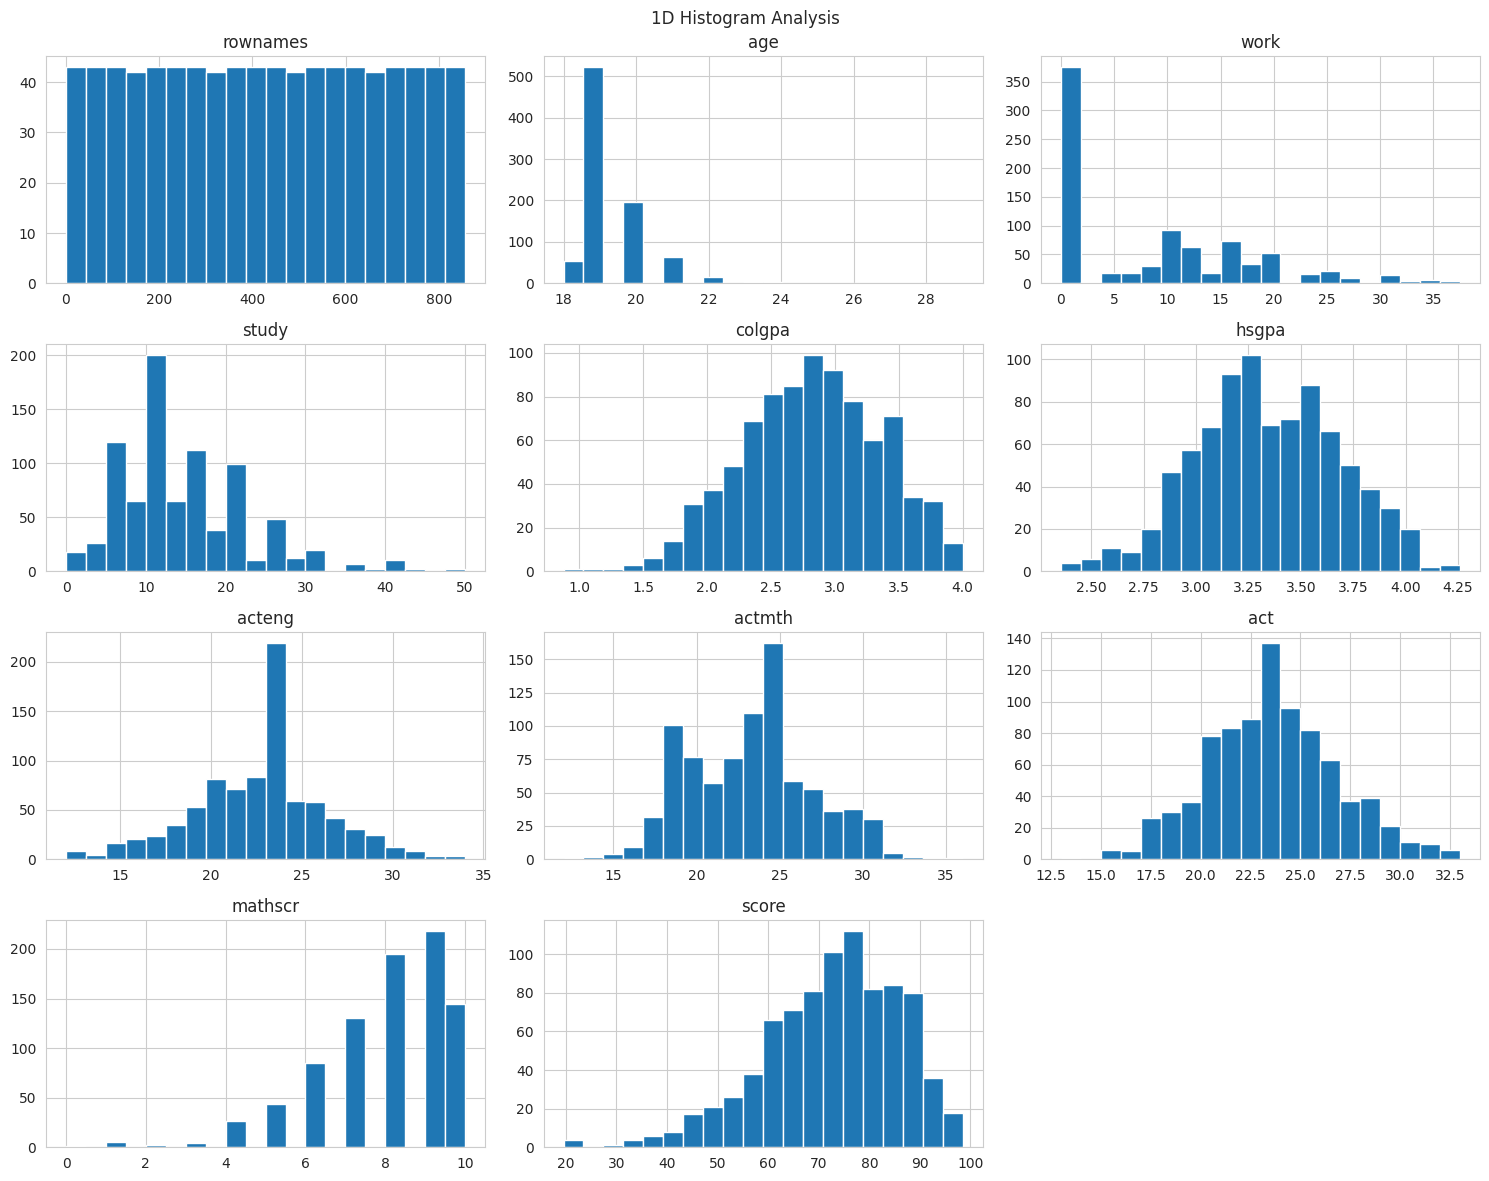

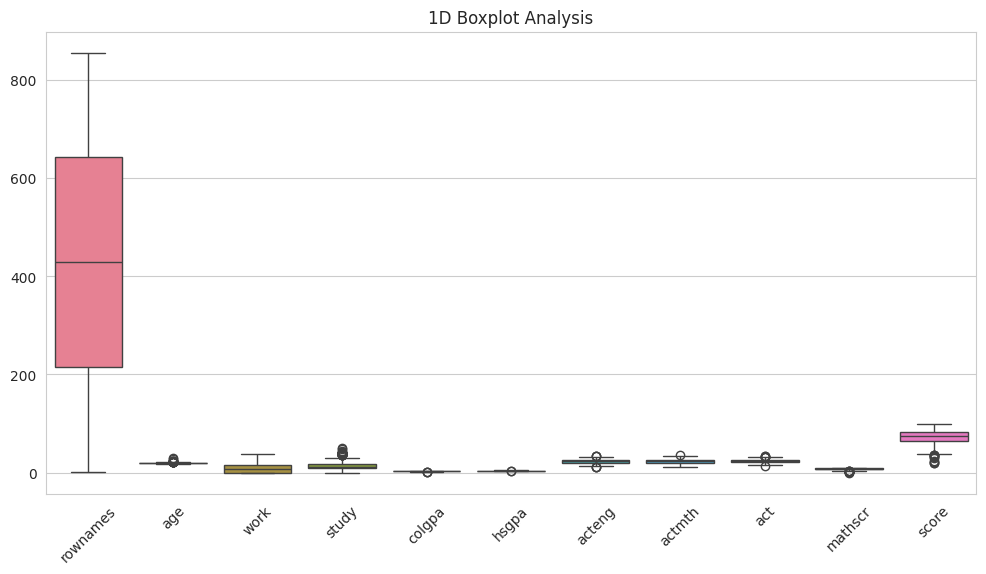

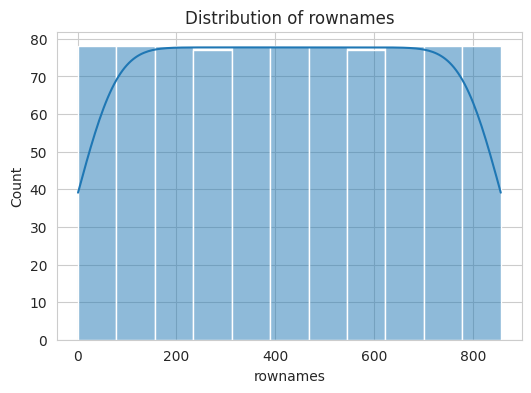

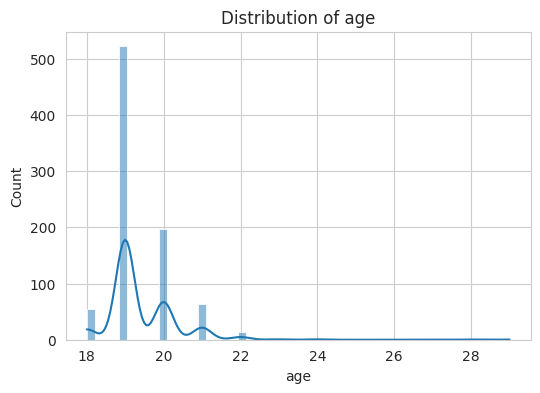

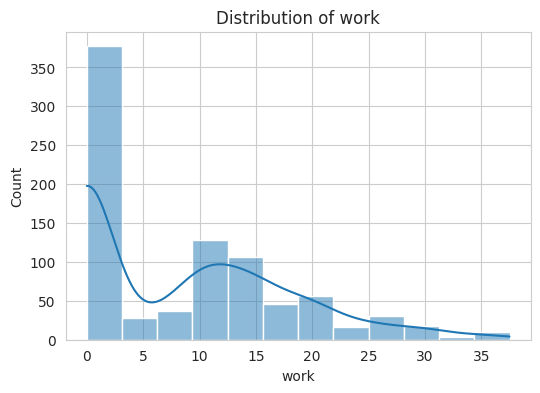

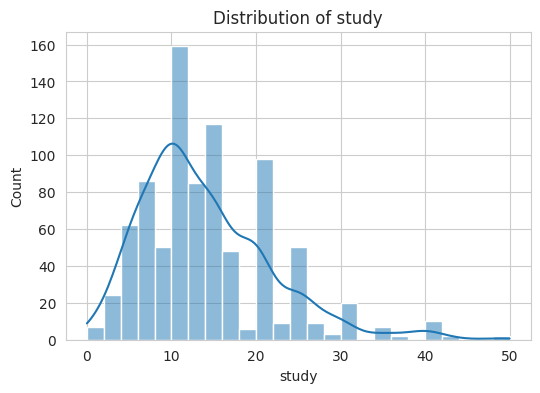

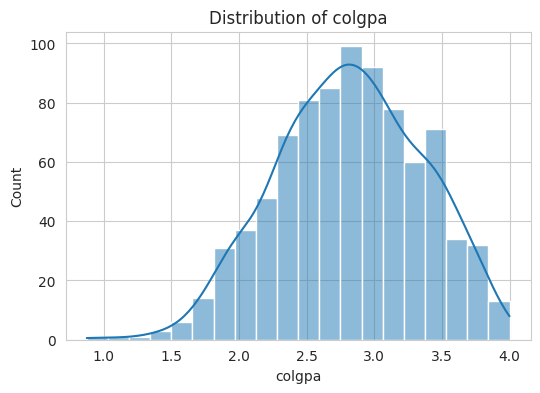

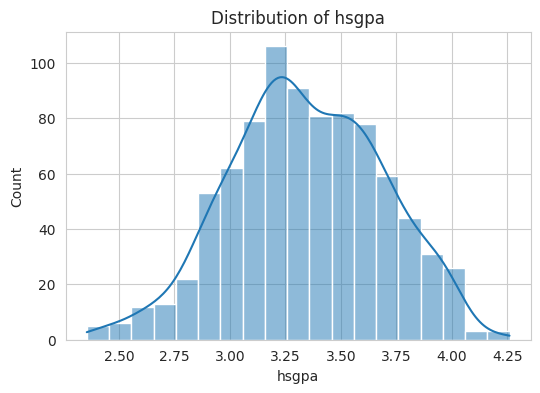

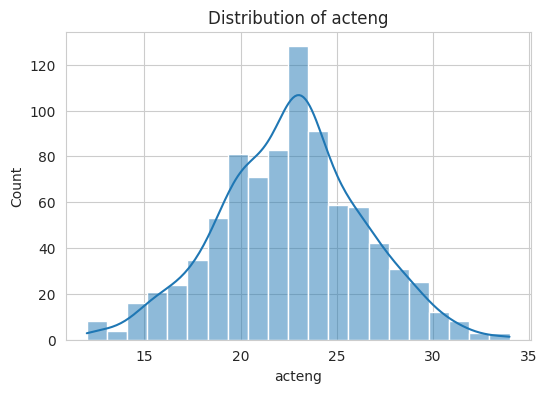

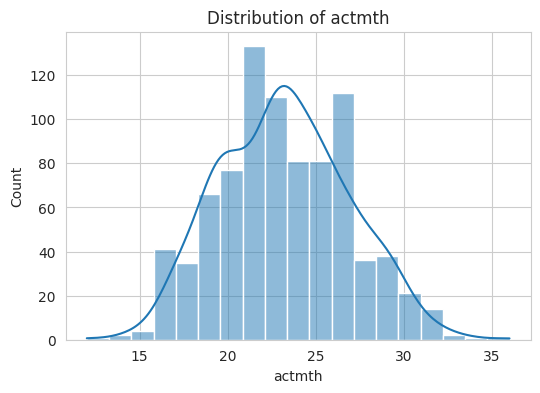

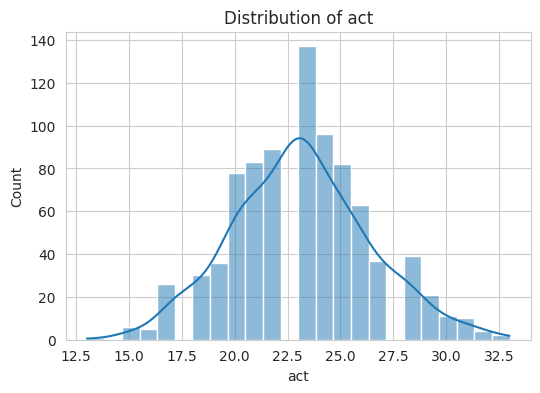

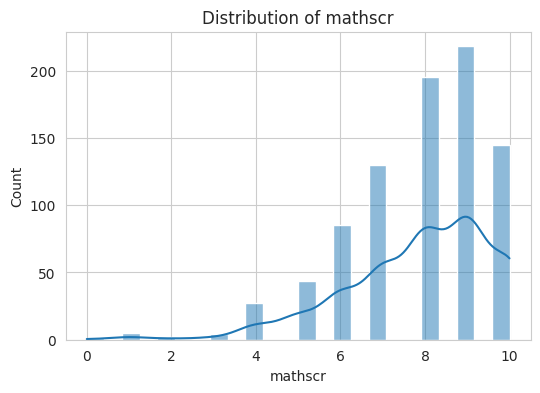

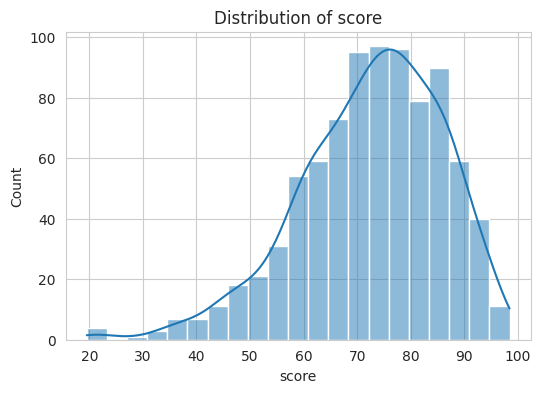

In [ ]:
# Histogram
numeric_df.hist(figsize=(15, 12), bins=20)
plt.suptitle("1D Histogram Analysis")
plt.tight_layout()
plt.show()

# Boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=numeric_df)
plt.title("1D Boxplot Analysis")
plt.xticks(rotation=45)
plt.show()

# Distribution plot
for col in numeric_df.columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

22. 2D Statistical Analysis

Correlation Matrix:


,rownames,age,work,study,colgpa,hsgpa,acteng,actmth,act,mathscr,score
rownames,1.000000,-0.266477,-0.125924,-0.049974,0.083476,0.038751,0.043282,0.071785,0.055416,0.073288,0.095738
age,-0.266477,1.000000,0.209845,0.050424,-0.105017,-0.031455,-0.028997,-0.021686,-0.019206,-0.022709,-0.068885
work,-0.125924,0.209845,1.000000,-0.007908,-0.124766,0.018489,0.032475,0.000169,0.023306,-0.026244,-0.167104
study,-0.049974,0.050424,-0.007908,1.000000,0.068338,0.073067,-0.081038,-0.099778,-0.137316,-0.016485,0.008800
colgpa,0.083476,-0.105017,-0.124766,0.068338,1.000000,0.479219,0.275652,0.293452,0.325039,0.191712,0.573519
hsgpa,0.038751,-0.031455,0.018489,0.073067,0.479219,1.000000,0.349136,0.388885,0.414270,0.261083,0.367549
acteng,0.043282,-0.028997,0.032475,-0.081038,0.275652,0.349136,1.000000,0.485362,0.837771,0.232989,0.268210
actmth,0.071785,-0.021686,0.000169,-0.099778,0.293452,0.388885,0.485362,1.000000,0.721841,0.463201,0.395067
act,0.055416,-0.019206,0.023306,-0.137316,0.325039,0.414270,0.837771,0.721841,1.000000,0.333260,0.377270
mathscr,0.073288,-0.022709,-0.026244,-0.016485,0.191712,0.261083,0.232989,0.463201,0.333260,1.000000,0.244440


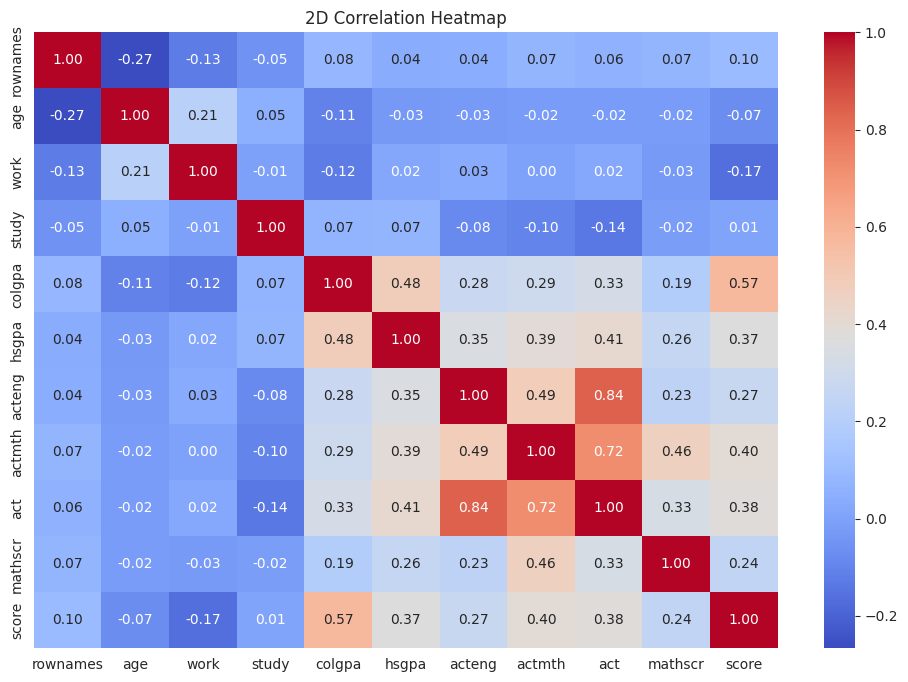

In [ ]:
# Correlation matrix
correlation = numeric_df.corr()

print("Correlation Matrix:")
display(correlation)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("2D Correlation Heatmap")
plt.show()

Scatter Plot

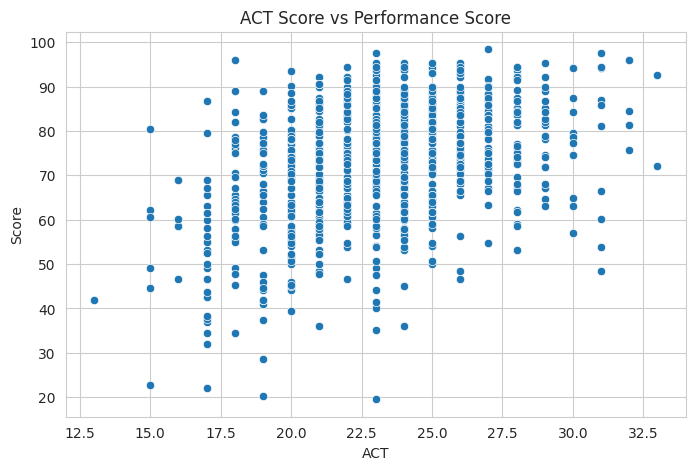

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='act', y='score')

plt.title("ACT Score vs Performance Score")
plt.xlabel("ACT")
plt.ylabel("Score")

plt.show()

Categorical vs Numerical Analysis

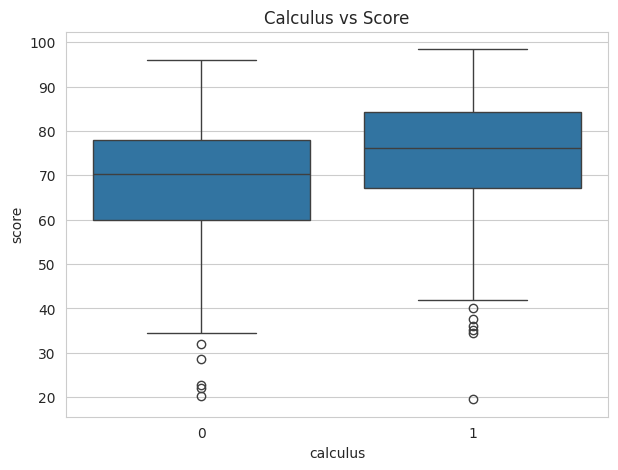

In [ ]:
if 'calculus' in df.columns:
    plt.figure(figsize=(7, 5))

    sns.boxplot(data=df, x='calculus', y='score')

    plt.title("Calculus vs Score")
    plt.show()

Correlation Analysis

In [ ]:
print("Correlation between ACT and Score:")

print(df['act'].corr(df['score']))

Correlation between ACT and Score:
0.3772697376272947


3D Statistical Analysis

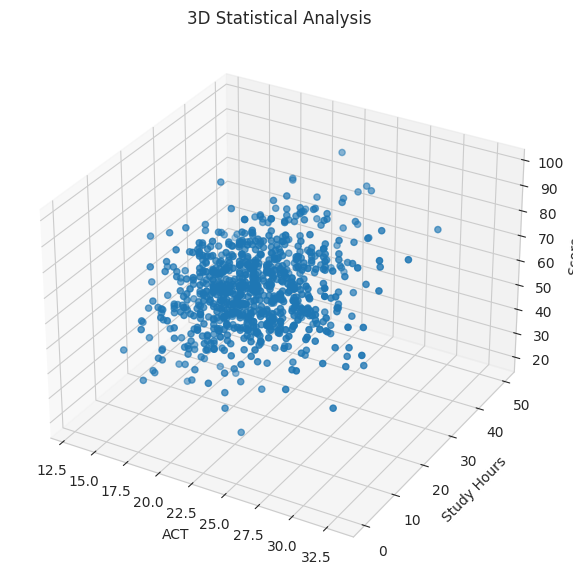

In [ ]:
fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    df['act'],
    df['study'],
    df['score']
)

ax.set_xlabel('ACT')
ax.set_ylabel('Study Hours')
ax.set_zlabel('Score')

ax.set_title("3D Statistical Analysis")

plt.show()

3D Visualization using Plotly

In [ ]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x='act',
    y='study',
    z='score',
    color='calculus',
    title='3D Relationship Between ACT, Study and Score'
)

fig.show()

K-Means Clustering

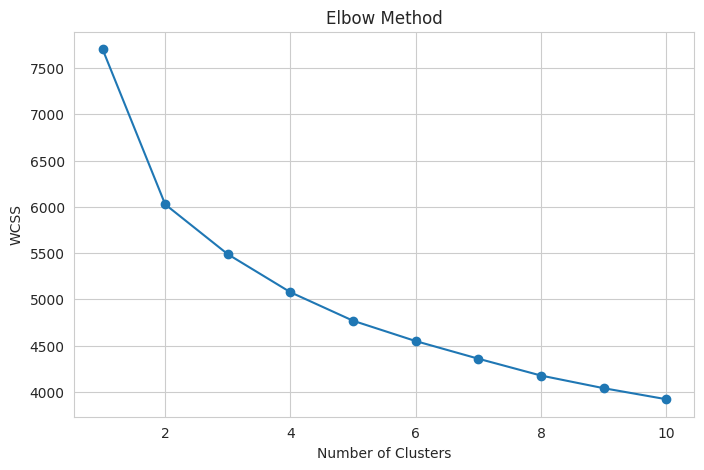

In [ ]:
# Select numerical columns
cluster_data = df.select_dtypes(include=np.number).drop(
    columns=['score', 'rownames'],
    errors='ignore'
)

# Standardization
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

# Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.show()

Apply K-Means

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(scaled_data)

print("K-Means Cluster Results:")

display(df[['score', 'KMeans_Cluster']].head(20))

print("\nCluster Counts:")

print(df['KMeans_Cluster'].value_counts())

print("\nSilhouette Score:")

print(silhouette_score(scaled_data, df['KMeans_Cluster']))

K-Means Cluster Results:


,score,KMeans_Cluster
0,84.43,1
1,57.38,2
2,66.39,2
3,81.15,1
4,95.90,1
5,83.61,1
6,76.23,2
7,84.43,1
8,79.51,1
9,46.72,2



Cluster Counts:
KMeans_Cluster
0    379
1    239
2    238
Name: count, dtype: int64

Silhouette Score:
0.12703154035667508


K-Means Visualization

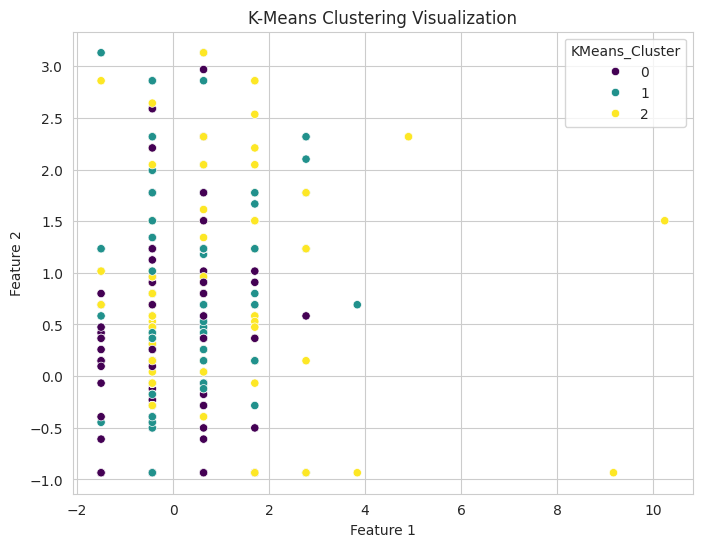

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=scaled_data[:, 0],
    y=scaled_data[:, 1],
    hue=df['KMeans_Cluster'],
    palette='viridis'
)

plt.title("K-Means Clustering Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

Hierarchical Clustering

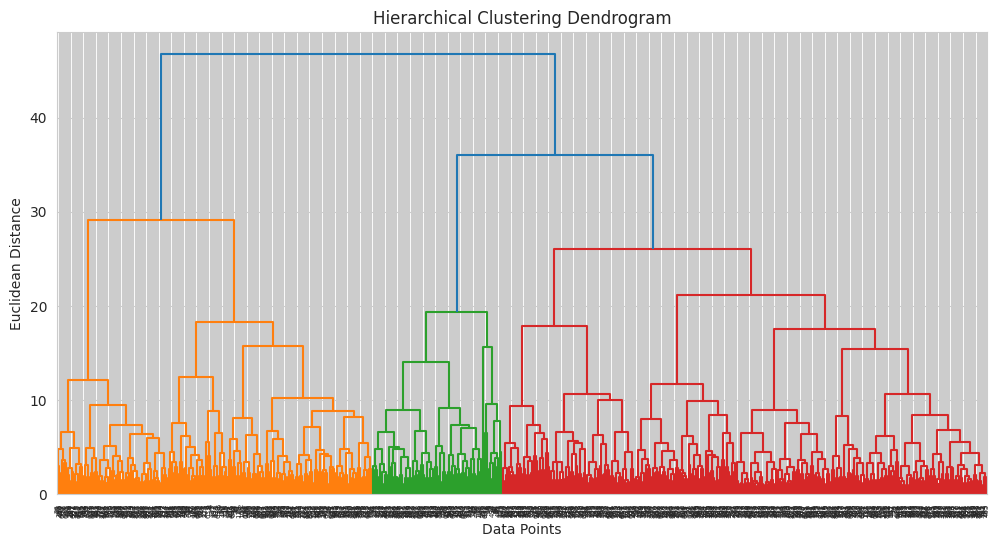

In [ ]:
# Create linkage matrix
linked = linkage(scaled_data, method='ward')

# Dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

Apply Hierarchical Clustering

In [ ]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    metric='euclidean',
    linkage='ward'
)

df['Hierarchical_Cluster'] = hierarchical.fit_predict(
    scaled_data
)

print("Hierarchical Clustering Results:")

display(
    df[['score', 'Hierarchical_Cluster']].head(20)
)

print("\nCluster Counts:")

print(df['Hierarchical_Cluster'].value_counts())

Hierarchical Clustering Results:


,score,Hierarchical_Cluster
0,84.43,0
1,57.38,1
2,66.39,0
3,81.15,0
4,95.90,0
5,83.61,0
6,76.23,2
7,84.43,0
8,79.51,0
9,46.72,2



Cluster Counts:
Hierarchical_Cluster
1    446
0    290
2    120
Name: count, dtype: int64


Compare Both Clustering Methods

In [ ]:
print("K-Means Silhouette Score:")

print(
    silhouette_score(
        scaled_data,
        df['KMeans_Cluster']
    )
)

print("\nHierarchical Silhouette Score:")

print(
    silhouette_score(
        scaled_data,
        df['Hierarchical_Cluster']
    )
)

print("\nClustering Comparison:")

comparison = df[
    ['KMeans_Cluster', 'Hierarchical_Cluster']
]

display(comparison.head(20))

K-Means Silhouette Score:
0.12703154035667508

Hierarchical Silhouette Score:
0.10357465085181188

Clustering Comparison:


,KMeans_Cluster,Hierarchical_Cluster
0,1,0
1,2,1
2,2,0
3,1,0
4,1,0
5,1,0
6,2,2
7,1,0
8,1,0
9,2,2


Final Results

In [ ]:
print("FINAL PROJECT RESULTS")

print("\nTotal Records:", len(df))

print("\nTotal Attributes:", len(df.columns))

print("\nK-Means Clustering:")
print(df['KMeans_Cluster'].value_counts())

print("\nHierarchical Clustering:")
print(df['Hierarchical_Cluster'].value_counts())

print("\nFinal Dataset:")
display(df.head(10))

# Save final dataset
df.to_csv("Phase_II_Final_Results.csv", index=False)

print("\nFile Saved Successfully!")

FINAL PROJECT RESULTS

Total Records: 856

Total Attributes: 20

K-Means Clustering:
KMeans_Cluster
0    379
1    239
2    238
Name: count, dtype: int64

Hierarchical Clustering:
Hierarchical_Cluster
1    446
0    290
2    120
Name: count, dtype: int64

Final Dataset:


,rownames,age,work,study,econhs,colgpa,hsgpa,acteng,actmth,act,mathscr,male,calculus,attexc,attgood,fathcoll,mothcoll,score,KMeans_Cluster,Hierarchical_Cluster
0,1,23,15.0,10.0,0,3.4909,3.355,24.0,26.0,27.0,10,1,1,0,0,1,1,84.43,1,0
1,2,23,0.0,22.5,1,2.1000,3.219,23.0,20.0,24.0,9,1,0,0,0,0,1,57.38,2,1
2,3,21,25.0,12.0,0,3.0851,3.306,21.0,24.0,21.0,8,1,1,1,0,0,1,66.39,2,0
3,4,22,30.0,40.0,0,2.6805,3.977,31.0,28.0,31.0,10,0,1,0,1,1,1,81.15,1,0
4,5,22,25.0,15.0,1,3.7454,3.890,28.0,31.0,32.0,8,1,1,0,1,0,1,95.90,1,0
5,6,22,0.0,30.0,0,3.0555,3.500,25.0,30.0,28.0,10,1,1,1,0,0,1,83.61,1,0
6,7,22,20.0,25.0,1,2.1666,3.000,15.0,19.0,18.0,9,0,1,0,1,0,0,76.23,2,2
7,8,22,20.0,15.0,0,3.2544,3.770,28.0,30.0,32.0,9,1,1,1,0,1,1,84.43,1,0
8,9,22,28.0,7.0,0,3.1298,3.927,28.0,28.0,30.0,6,0,0,1,0,0,1,79.51,1,0
9,10,21,22.5,25.0,0,2.2424,2.770,18.0,19.0,17.0,9,0,1,0,1,0,0,46.72,2,2



File Saved Successfully!


Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.decomposition import PCA

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

Load Dataset

In [ ]:
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/econmath.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

display(df.head())

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Loaded Successfully


,rownames,age,work,study,econhs,colgpa,hsgpa,acteng,actmth,act,mathscr,male,calculus,attexc,attgood,fathcoll,mothcoll,score
0,1,23,15.0,10.0,0,3.4909,3.355,24.0,26.0,27.0,10,1,1,0,0,1,1,84.43
1,2,23,0.0,22.5,1,2.1000,3.219,23.0,20.0,24.0,9,1,0,0,0,0,1,57.38
2,3,21,25.0,12.0,0,3.0851,3.306,21.0,24.0,21.0,8,1,1,1,0,0,1,66.39
3,4,22,30.0,40.0,0,2.6805,3.977,31.0,28.0,31.0,10,0,1,0,1,1,1,81.15
4,5,22,25.0,15.0,1,3.7454,3.890,28.0,31.0,32.0,8,1,1,0,1,0,1,95.90


Dataset Shape: (856, 18)

Column Names:
['rownames', 'age', 'work', 'study', 'econhs', 'colgpa', 'hsgpa', 'acteng', 'actmth', 'act', 'mathscr', 'male', 'calculus', 'attexc', 'attgood', 'fathcoll', 'mothcoll', 'score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 856 entries, 0 to 855
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  856 non-null    int64  
 1   age       856 non-null    int64  
 2   work      856 non-null    float64
 3   study     856 non-null    float64
 4   econhs    856 non-null    int64  
 5   colgpa    856 non-null    float64
 6   hsgpa     856 non-null    float64
 7   acteng    814 non-null    float64
 8   actmth    814 non-null    float64
 9   act       814 non-null    float64
 10  mathscr   856 non-null    int64  
 11  male      856 non-null    int64  
 12  calculus  856 non-null    int64  
 13  attexc    856 non-null    int64  
 14  attgood   856 non-null    

Data Cleaning

In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate values
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Convert target variable into numeric
df['score'] = pd.to_numeric(df['score'], errors='coerce')

# Remove records where target score is missing
df = df.dropna(subset=['score'])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
display(df.head())

print("Final Dataset Shape:", df.shape)

Missing Values:
rownames     0
age          0
work         0
study        0
econhs       0
colgpa       0
hsgpa        0
acteng      42
actmth      42
act         42
mathscr      0
male         0
calculus     0
attexc       0
attgood      0
fathcoll     0
mothcoll     0
score        0
dtype: int64

Duplicate Records:
0

Missing Values After Cleaning:
rownames     0
age          0
work         0
study        0
econhs       0
colgpa       0
hsgpa        0
acteng      42
actmth      42
act         42
mathscr      0
male         0
calculus     0
attexc       0
attgood      0
fathcoll     0
mothcoll     0
score        0
dtype: int64

Cleaned Dataset:


,rownames,age,work,study,econhs,colgpa,hsgpa,acteng,actmth,act,mathscr,male,calculus,attexc,attgood,fathcoll,mothcoll,score
0,1,23,15.0,10.0,0,3.4909,3.355,24.0,26.0,27.0,10,1,1,0,0,1,1,84.43
1,2,23,0.0,22.5,1,2.1000,3.219,23.0,20.0,24.0,9,1,0,0,0,0,1,57.38
2,3,21,25.0,12.0,0,3.0851,3.306,21.0,24.0,21.0,8,1,1,1,0,0,1,66.39
3,4,22,30.0,40.0,0,2.6805,3.977,31.0,28.0,31.0,10,0,1,0,1,1,1,81.15
4,5,22,25.0,15.0,1,3.7454,3.890,28.0,31.0,32.0,8,1,1,0,1,0,1,95.90


Final Dataset Shape: (856, 18)


Data Handling and Feature Selection

In [ ]:
# Separate independent and dependent variables

X = df.drop(columns=['score', 'rownames'], errors='ignore')

y = df['score']

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTarget Variable: score")

Numerical Features:
['age', 'work', 'study', 'econhs', 'colgpa', 'hsgpa', 'acteng', 'actmth', 'act', 'mathscr', 'male', 'calculus', 'attexc', 'attgood', 'fathcoll', 'mothcoll']

Categorical Features:
[]

Target Variable: score


Train and Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (684, 16)
Testing Data: (172, 16)


Data Preprocessing

In [ ]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Transform training and testing data
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed")

print("Training Data Shape:", X_train_processed.shape)

print("Testing Data Shape:", X_test_processed.shape)

Preprocessing Completed
Training Data Shape: (684, 16)
Testing Data Shape: (172, 16)


Dimensionality Reduction Using PCA

In [ ]:
# Apply PCA
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_processed)

X_test_pca = pca.transform(X_test_processed)

print("Original Number of Features:",
      X_train_processed.shape[1])

print("Reduced Number of Features:",
      X_train_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(sum(pca.explained_variance_ratio_))

Original Number of Features: 16
Reduced Number of Features: 13

Explained Variance Ratio:
[0.20820955 0.12149688 0.09327731 0.09003752 0.0742779  0.06622264
 0.06369598 0.05109766 0.04552627 0.04046986 0.03972676 0.03539656
 0.02877546]

Total Explained Variance:
0.9582103497195554


PCA Visualization

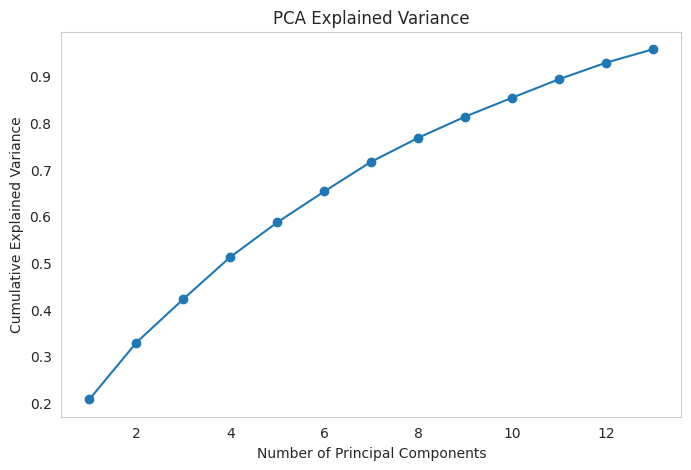

In [ ]:
# Explained variance graph

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.xlabel("Number of Principal Components")

plt.ylabel("Cumulative Explained Variance")

plt.title("PCA Explained Variance")

plt.grid()

plt.show()

2D PCA Visualization

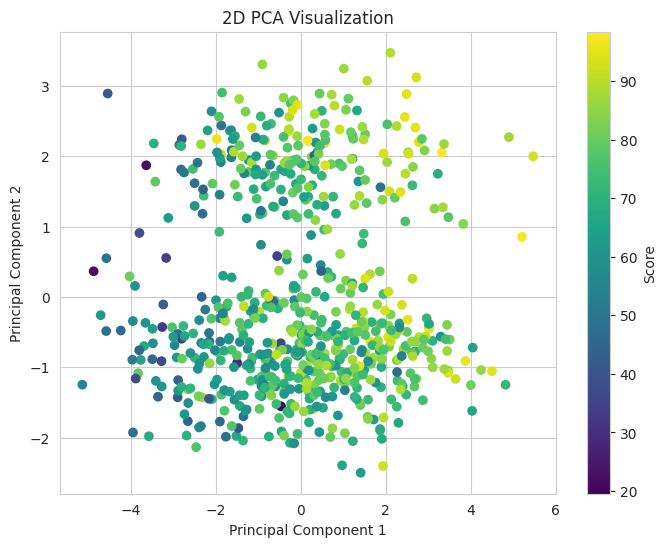

In [ ]:
# PCA with 2 components for visualization
pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(X_train_processed)

plt.figure(figsize=(8,6))

plt.scatter(
    X_pca_2d[:,0],
    X_pca_2d[:,1],
    c=y_train,
    cmap='viridis'
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("2D PCA Visualization")

plt.colorbar(label="Score")

plt.show()

Model Building – Linear Regression

In [ ]:
lr_model = LinearRegression()

lr_model.fit(
    X_train_processed,
    y_train
)

lr_predictions = lr_model.predict(
    X_test_processed
)

print("Linear Regression Model Built Successfully")

print("\nFirst 10 Predictions:")

print(lr_predictions[:10])

Linear Regression Model Built Successfully

First 10 Predictions:
[73.86299514 71.19309289 74.91541404 82.56755642 70.88043506 74.501491
 79.54983686 73.42248241 74.40052635 73.91266054]


Model Building – Decision Tree Regression

In [ ]:
dt_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

dt_model.fit(
    X_train_processed,
    y_train
)

dt_predictions = dt_model.predict(
    X_test_processed
)

print("Decision Tree Model Built Successfully")

print("\nFirst 10 Predictions:")

print(dt_predictions[:10])

Decision Tree Model Built Successfully

First 10 Predictions:
[67.841625   76.75043478 76.75043478 90.495      61.92174603 78.39632653
 80.90054054 67.841625   74.65265306 74.65265306]


Model Building – Random Forest Regression

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

rf_model.fit(
    X_train_processed,
    y_train
)

rf_predictions = rf_model.predict(
    X_test_processed
)

print("Random Forest Model Built Successfully")

print("\nFirst 10 Predictions:")

print(rf_predictions[:10])

Random Forest Model Built Successfully

First 10 Predictions:
[72.08411153 71.14420649 73.0882455  84.49184959 66.84208916 77.07352677
 78.69393712 73.05418779 76.37229647 75.55540276]


PCA-Based Model Building

In [ ]:
pca_model = LinearRegression()

pca_model.fit(
    X_train_pca,
    y_train
)

pca_predictions = pca_model.predict(
    X_test_pca
)

print("PCA-Based Model Built Successfully")

print("\nFirst 10 Predictions:")

print(pca_predictions[:10])

PCA-Based Model Built Successfully

First 10 Predictions:
[72.35304776 71.03616932 74.94295519 83.70612034 72.56679542 73.33929158
 78.68094387 73.93633941 74.03691443 74.52579261]


Model Evaluation

In [ ]:
models = {
    "Linear Regression": lr_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "PCA + Linear Regression": pca_predictions
}

results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(results_df.sort_values(
    by="R2 Score",
    ascending=False
))

MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,8.231954,108.116052,10.397887,0.390865
3,PCA + Linear Regression,8.319232,110.009489,10.488541,0.380197
2,Random Forest,8.259564,111.624410,10.565245,0.371099
1,Decision Tree,8.812027,137.185583,11.712625,0.227085


Model Comparison Visualization

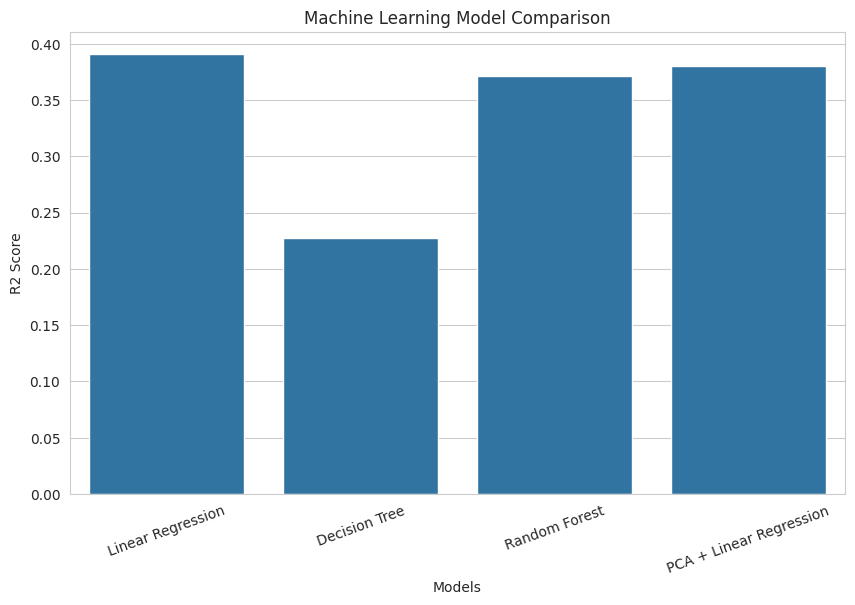

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Machine Learning Model Comparison")

plt.xlabel("Models")

plt.ylabel("R2 Score")

plt.xticks(rotation=20)

plt.show()

Actual vs Predicted Visualization

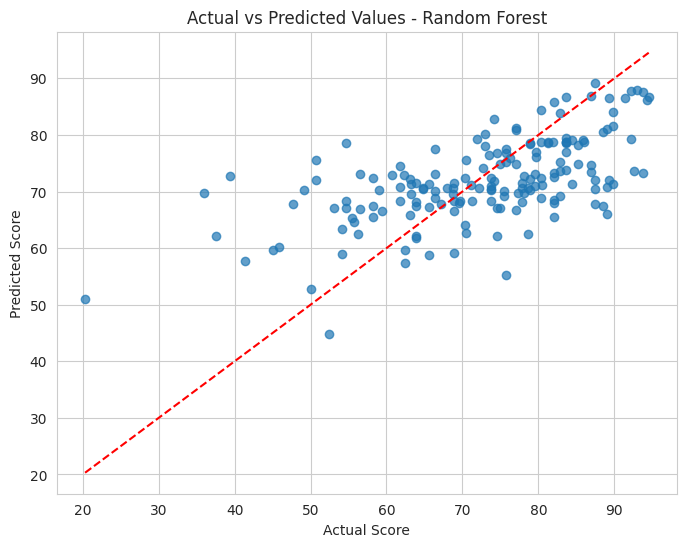

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Score")

plt.ylabel("Predicted Score")

plt.title("Actual vs Predicted Values - Random Forest")

plt.show()

Actual vs Predicted Visualization

Feature Importance

Feature Importance:


,Feature,Importance
4,num__colgpa,0.553125
8,num__act,0.119031
7,num__actmth,0.071170
9,num__mathscr,0.045388
5,num__hsgpa,0.041407
1,num__work,0.039852
6,num__acteng,0.030249
11,num__calculus,0.029108
2,num__study,0.028811
0,num__age,0.016718


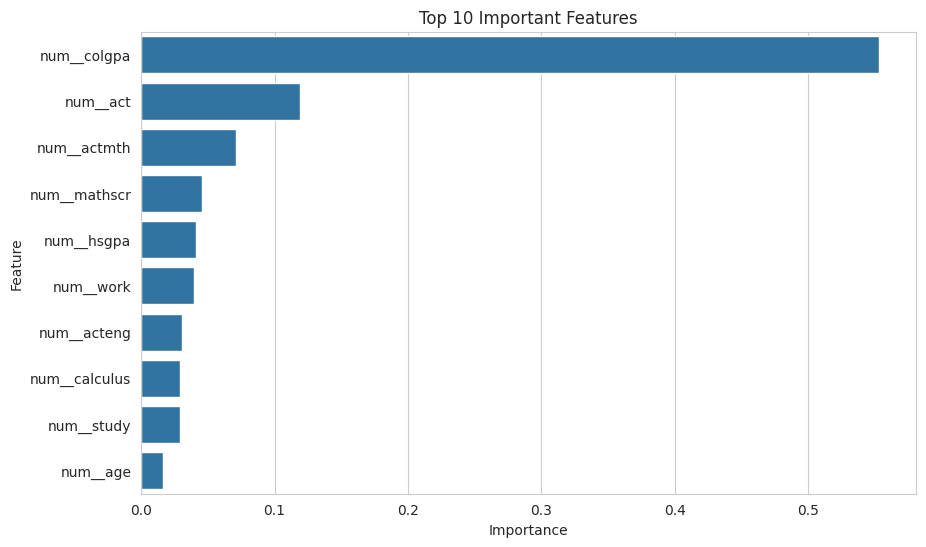

In [ ]:
feature_names = preprocessor.get_feature_names_out()

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")

display(feature_importance)

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")

plt.show()

Final Prediction Table

In [ ]:
prediction_table = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": rf_predictions
})

prediction_table["Difference"] = (
    prediction_table["Actual Score"] -
    prediction_table["Predicted Score"]
)

print("Final Prediction Results:")

display(prediction_table.head(20))

Final Prediction Results:


,Actual Score,Predicted Score,Difference
0,50.78,72.084112,-21.304112
1,71.09,71.144206,-0.054206
2,79.51,73.088245,6.421755
3,80.33,84.491850,-4.161850
4,56.56,66.842089,-10.282089
5,79.69,77.073527,2.616473
6,81.25,78.693937,2.556063
7,66.39,73.054188,-6.664188
8,73.44,76.372296,-2.932296
9,50.78,75.555403,-24.775403


Identify Best Model

In [ ]:
best_model = results_df.loc[
    results_df["R2 Score"].idxmax()
]

print("BEST MACHINE LEARNING MODEL")

print("Model Name:", best_model["Model"])

print("MAE:", best_model["MAE"])

print("MSE:", best_model["MSE"])

print("RMSE:", best_model["RMSE"])

print("R2 Score:", best_model["R2 Score"])

BEST MACHINE LEARNING MODEL
Model Name: Linear Regression
MAE: 8.231953835231197
MSE: 108.11605239261189
RMSE: 10.397886919591494
R2 Score: 0.3908650981331918


Save Final Project Results

In [ ]:
# Save cleaned dataset
df.to_csv(
    "Cleaned_Econmath_Dataset.csv",
    index=False
)

# Save model comparison
results_df.to_csv(
    "Model_Performance.csv",
    index=False
)

# Save predictions
prediction_table.to_csv(
    "Final_Predictions.csv",
    index=False
)

# Save feature importance
feature_importance.to_csv(
    "Feature_Importance.csv",
    index=False
)

print("All Project Files Saved Successfully!")

All Project Files Saved Successfully!
